In [29]:
## 4. Data Loading
import pandas as pd 

pd.options.display.float_format = '{:,.2f}'.format

file_path = r"C:\Users\POP\Downloads\archive\Global Superstore.xls"

df = pd.read_excel(file_path)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless","2,892.51",5,0.10,-96.54,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed","2,832.96",8,0.00,311.52,903.04,Critical


## 5. Data Overview 

In [30]:
df.shape

(51290, 24)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  str           
 2   Order Date      51290 non-null  datetime64[us]
 3   Ship Date       51290 non-null  datetime64[us]
 4   Ship Mode       51290 non-null  str           
 5   Customer ID     51290 non-null  str           
 6   Customer Name   51290 non-null  str           
 7   Segment         51290 non-null  str           
 8   City            51290 non-null  str           
 9   State           51290 non-null  str           
 10  Country         51290 non-null  str           
 11  Postal Code     9994 non-null   float64       
 12  Market          51290 non-null  str           
 13  Region          51290 non-null  str           
 14  Product ID      51290 non-null  str           
 15  Category     

In [32]:
df.groupby("Country")["Postal Code"].count().sort_values(ascending=False).head(10)

Country
United States    9994
Albania             0
Afghanistan         0
Angola              0
Argentina           0
Armenia             0
Australia           0
Austria             0
Azerbaijan          0
Bahrain             0
Name: Postal Code, dtype: int64

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df["Order ID"].nunique()

25035

In [35]:
df["Customer ID"].nunique()

1590

In [36]:
df[["Order Date", "Ship Date"]].agg(["min", "max"])

,Order Date,Ship Date
min,2011-01-01,2011-01-03
max,2014-12-31,2015-01-07


In [37]:
df[["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]].describe()

,Sales,Quantity,Discount,Profit,Shipping Cost
count,"51,290.00","51,290.00","51,290.00","51,290.00","51,290.00"
mean,246.49,3.48,0.14,28.61,26.38
std,487.57,2.28,0.21,174.34,57.30
min,0.44,1.00,0.00,"-6,599.98",0.00
25%,30.76,2.00,0.00,0.00,2.61
50%,85.05,3.00,0.00,9.24,7.79
75%,251.05,5.00,0.20,36.81,24.45
max,"22,638.48",14.00,0.85,"8,399.98",933.57


### Initial Observations

- The dataset contains both profitable and loss-making records.
- Sales values show a noticeable difference between the mean (246.49) and median (85.05).
- Discount values range from 0% to 85%.
- The five selected numerical columns contain no missing values.
- Maximum Sales, Profit, and Shipping Cost values are considerably higher than their medians and may require further investigation.

## 6. Data Quality Assessment

### Data Quality Findings

- No fully duplicated rows were found.
- The Postal Code column contains 41,296 missing values (approximately 80.5%).
- Available Postal Code values belong to the United States only.
- The selected numerical columns contain no missing values.
- Sales and Quantity values are all positive.
- Discount values range from 0% to 85%.
- Negative Profit values represent loss-making records and should not be removed.
### Data Cleaning Decisions

- Keep the original Postal Code column without filling missing values.
- Exclude Postal Code from global performance analysis because its coverage is limited to one country.
- No duplicate rows need to be removed.

In [38]:
(df["Ship Date"] < df["Order Date"]).sum()

np.int64(0)

- No records have a Ship Date earlier than the Order Date.

## 7. Exploratory Data Analysis
### 7.1 Sales and Profit Analysis Over Time

In [39]:
df.groupby(df["Order Date"].dt.year)[["Sales", "Profit"]].sum()

,Sales,Profit
Order Date,,
2011,"2,259,450.90","248,940.81"
2012,"2,677,438.69","307,415.28"
2013,"3,405,746.45","406,935.23"
2014,"4,299,865.87","504,165.97"


### Business Insights

- Sales increased consistently from 2011 to 2014.
- Total Profit also increased throughout the four years.
- Profit Margin slightly decreased in 2014 compared to 2013, despite the increase in total sales and profit.

In [40]:
df.groupby(df["Order Date"].dt.year)["Discount"].mean() * 100

Order Date
2011   14.82
2012   14.13
2013   14.03
2014   14.33
Name: Discount, dtype: float64

In [41]:
df.groupby([df["Order Date"].dt.year, "Category"])["Sales"].sum()

Order Date  Category       
2011        Furniture           756,192.38
            Office Supplies     675,606.45
            Technology          827,652.06
2012        Furniture           858,902.56
            Office Supplies     795,094.63
            Technology        1,023,441.51
2013        Furniture         1,117,723.55
            Office Supplies   1,010,717.64
            Technology        1,277,305.25
2014        Furniture         1,378,055.69
            Office Supplies   1,305,651.51
            Technology        1,616,158.67
Name: Sales, dtype: float64

In [42]:
category_year = df.groupby([df["Order Date"].dt.year, "Category"]).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum")
)

category_year["Sales Share"] = (
    category_year["Sales"]
    / category_year.groupby(level=0)["Sales"].transform("sum")
    * 100
)

category_year["Profit Margin"] = category_year["Profit"] / category_year["Sales"] * 100

category_year.round(2)

Sales     Profit  Sales Share  Profit Margin
Order Date Category                                                           
2011       Furniture         756,192.38  53,696.93        33.47           7.10
           Office Supplies   675,606.45  85,996.53        29.90          12.73
           Technology        827,652.06 109,247.35        36.63          13.20
2012       Furniture         858,902.56  58,132.83        32.08           6.77
           Office Supplies   795,094.63 103,305.51        29.70          12.99
           Technology      1,023,441.51 145,976.94        38.22          14.26
2013       Furniture       1,117,723.55  84,062.90        32.82           7.52
           Office Supplies 1,010,717.64 149,245.74        29.68          14.77
           Technology      1,277,305.25 173,626.59        37.50          13.59
2014       Furniture       1,378,055.69  89,312.06        32.05           6.48
           Office Supplies 1,305,651.51 179,926.06        30.36          13.78
           Technology      1,616,158.67 234,927.85        37.59          14.54

In [43]:
sub_category_year = (
    df[
        (df["Order Date"].dt.year.isin([2013, 2014]))
        & (df["Category"].isin(["Furniture", "Office Supplies"]))
    ]
    .groupby([df["Order Date"].dt.year, "Sub-Category"])
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
)

sub_category_year["Profit Margin"] = (
    sub_category_year["Profit"] / sub_category_year["Sales"] * 100
)

sub_category_year.round(2)

Sales     Profit  Profit Margin
Order Date Sub-Category                                     
2013       Appliances   254,951.13  41,485.52          16.27
           Art           98,007.03  15,629.79          15.95
           Binders      121,075.09  21,523.63          17.78
           Bookcases    376,025.80  43,049.24          11.45
           Chairs       427,514.37  40,449.49           9.46
           Envelopes     50,805.26   9,571.95          18.84
           Fasteners     21,596.89   2,912.22          13.48
           Furnishings  111,819.85  14,604.65          13.06
           Labels        18,380.79   3,606.57          19.62
           Paper         70,512.55  16,879.65          23.94
           Storage      309,475.80  32,011.03          10.34
           Supplies      65,913.10   5,625.37           8.53
           Tables       202,363.54 -14,040.49          -6.94
2014       Appliances   359,786.78  53,040.50          14.74
           Art          127,587.65  20,083.76          15.74
           Binders      160,419.58  22,356.49          13.94
           Bookcases    513,196.71  63,219.05          12.32
           Chairs       493,378.28  41,248.27           8.36
           Envelopes     54,098.63   8,360.09          15.45
           Fasteners     28,559.16   3,672.31          12.86
           Furnishings  128,020.31  15,390.65          12.02
           Labels        25,888.51   5,054.72          19.52
           Paper         79,600.81  20,975.83          26.35
           Storage      383,427.29  39,016.95          10.18
           Supplies      86,283.09   7,365.41           8.54
           Tables       243,460.40 -30,545.91         -12.55

### Sub-Category Insights

- Tables experienced a significant decline in profitability between 2013 and 2014.
- Tables Profit Margin decreased from -6.94% to -12.55%.
- Binders and Envelopes also experienced noticeable declines in Profit Margin.
- Paper and Bookcases showed improvements in profitability.
- The findings indicate that profitability changes differ across product sub-categories.

In [44]:
discount_analysis = (
    df[
        (df["Order Date"].dt.year.isin([2013, 2014]))
        & (df["Sub-Category"].isin(["Tables", "Binders", "Envelopes"]))
    ]
    .groupby([df["Order Date"].dt.year, "Sub-Category"])
    .agg(
        Average_Discount=("Discount", "mean"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
    )
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"] / discount_analysis["Sales"] * 100
)

discount_analysis.round(2)

Average_Discount      Sales     Profit  Profit_Margin
Order Date Sub-Category                                                       
2013       Binders                   0.17 121,075.09  21,523.63          17.78
           Envelopes                 0.12  50,805.26   9,571.95          18.84
           Tables                    0.30 202,363.54 -14,040.49          -6.94
2014       Binders                   0.18 160,419.58  22,356.49          13.94
           Envelopes                 0.14  54,098.63   8,360.09          15.45
           Tables                    0.29 243,460.40 -30,545.91         -12.55

### 7.3 Regional Performance Analysis

In [45]:
region_analysis = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

region_analysis["Profit Margin"] = (
    region_analysis["Profit"] / region_analysis["Sales"] * 100
)

region_analysis.sort_values("Profit", ascending=False).round(2)

,Sales,Profit,Profit Margin
Region,,,
Central,"2,822,302.52","311,403.98",11.03
North,"1,248,165.60","194,597.95",15.59
North Asia,"848,309.78","165,578.42",19.52
South,"1,600,907.04","140,355.77",8.77
Central Asia,"752,826.57","132,480.19",17.60
Oceania,"1,100,184.61","120,089.11",10.92
West,"725,457.82","108,418.45",14.94
East,"678,781.24","91,522.78",13.48
Africa,"783,773.21","88,871.63",11.34


### 7.4 Customer Segment Analysis

In [46]:
segment_analysis = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

segment_analysis["Profit Margin"] = (
    segment_analysis["Profit"] / segment_analysis["Sales"] * 100
)

segment_analysis.sort_values("Profit", ascending=False).round(2)

,Sales,Profit,Profit Margin
Segment,,,
Consumer,"6,507,949.42","749,239.78",11.51
Corporate,"3,824,697.52","441,208.33",11.54
Home Office,"2,309,854.97","277,009.18",11.99


### Customer Segment Insights

- Consumer generated the highest total sales and profit.
- Home Office achieved the highest profit margin at 11.99%.
- Profit margins are very similar across all customer segments.
- No significant profitability difference was observed between the segments.

## 8. Key Business Insights

### 1. Overall Business Performance
- Sales and total profit increased consistently from 2011 to 2014.
- Overall Profit Margin slightly decreased in 2014 compared to 2013.

### 2. Product Performance
- Technology generated the highest total profit among the three main categories.
- Furniture showed lower profitability compared to other categories.
- Tables generated an overall loss of approximately 64,083.

### 3. Discount Impact
- Higher average discounts were observed alongside lower profit margins in Binders and Envelopes.
- Tables profitability declined despite a slight decrease in average discount.
- Discounts alone do not explain the changes in profitability.

### 4. Regional Performance
- Central generated the highest total sales and profit.
- Canada achieved the highest Profit Margin, despite having relatively low sales.
- Southeast Asia showed a low Profit Margin of 2.02%, making it a priority for further investigation.

### 5. Customer Segments
- Consumer generated the highest total sales and profit.
- Home Office achieved the highest Profit Margin.
- Profit Margins were very similar across all customer segments.

## 9. Business Recommendations

### 1. Tables Profitability
- Review pricing and discount policies for Tables.
- Investigate products with recurring losses.
- Review product and shipping costs before making pricing decisions.

### 2. Regional Performance
- Investigate the low Profit Margin in Southeast Asia.
- Analyze product performance and discount patterns within this region.
- Explore growth opportunities in high-margin regions such as Canada.

### 3. Discount Management
- Review discount strategies for Binders and Envelopes.
- Evaluate whether discount levels are reducing product profitability.
- Avoid increasing discounts without measuring their impact on profit.

### 4. Product Performance
- Monitor Furniture profitability.
- Maintain the strong performance of Technology products.
- Identify opportunities to improve low-margin products.

### 5. Customer Segments
- Maintain the strong sales performance of the Consumer segment.
- Explore opportunities to grow Home Office sales while maintaining its higher Profit Margin.

## 10. Visual Report

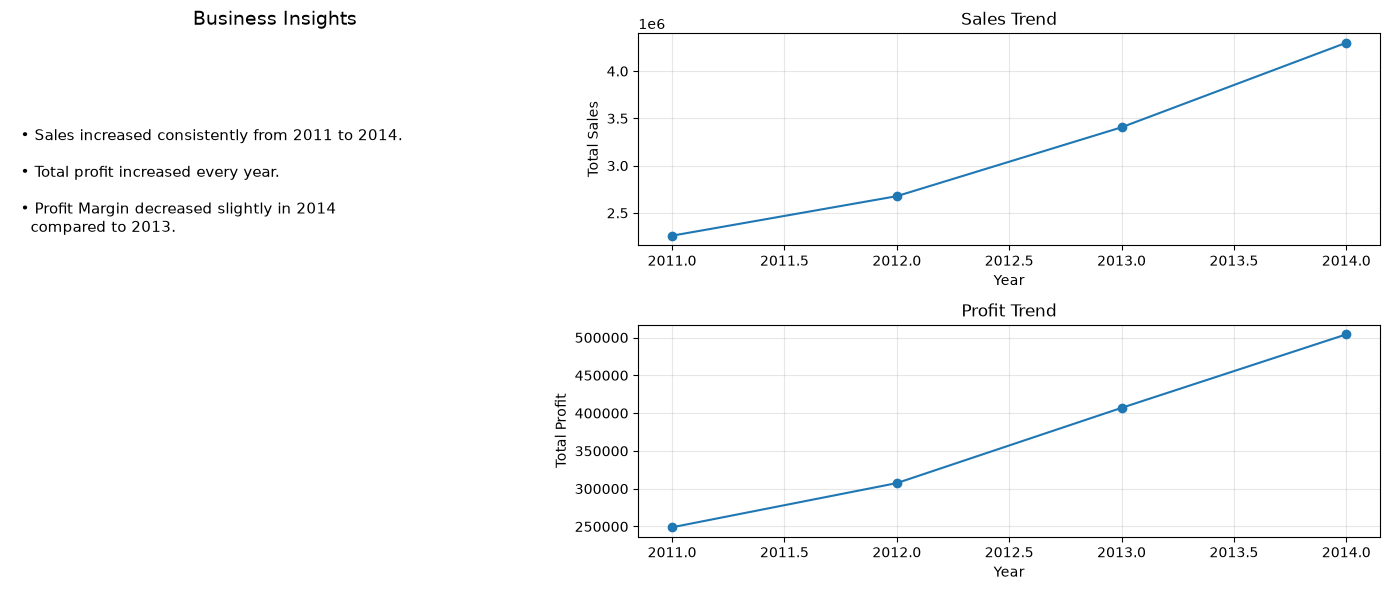

In [48]:
import matplotlib.pyplot as plt

# Calculate yearly sales and profit
yearly_performance = df.groupby(
    df["Order Date"].dt.year
)[["Sales", "Profit"]].sum()

# Create the report layout
fig = plt.figure(figsize=(14, 6))
grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.4])

# Left side: Business Insights
text_ax = fig.add_subplot(grid[:, 0])
text_ax.axis("off")
text_ax.set_title("Business Insights", fontsize=14)

insights = """
• Sales increased consistently from 2011 to 2014.

• Total profit increased every year.

• Profit Margin decreased slightly in 2014
  compared to 2013.
"""

text_ax.text(
    0.02, 0.85, insights,
    fontsize=11,
    verticalalignment="top"
)

# Right side: Sales Chart
sales_ax = fig.add_subplot(grid[0, 1])

yearly_performance["Sales"].plot(
    kind="line",
    marker="o",
    ax=sales_ax
)

sales_ax.set_title("Sales Trend")
sales_ax.set_ylabel("Total Sales")
sales_ax.set_xlabel("Year")
sales_ax.grid(alpha=0.3)

# Right side: Profit Chart
profit_ax = fig.add_subplot(grid[1, 1])

yearly_performance["Profit"].plot(
    kind="line",
    marker="o",
    ax=profit_ax
)

profit_ax.set_title("Profit Trend")
profit_ax.set_ylabel("Total Profit")
profit_ax.set_xlabel("Year")
profit_ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

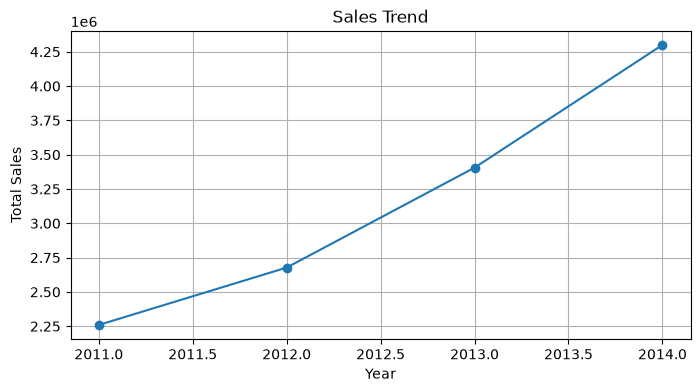

In [49]:
%matplotlib inline

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    yearly_performance.index,
    yearly_performance["Sales"],
    marker="o"
)

plt.title("Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.grid()

plt.show()

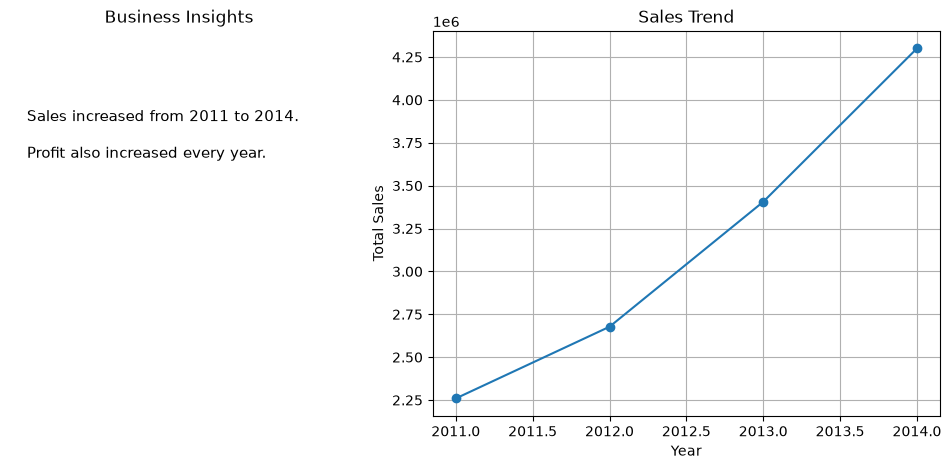

In [50]:
fig, (text_ax, sales_ax) = plt.subplots(
    1, 2,
    figsize=(12, 5),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

text_ax.axis("off")

text_ax.set_title("Business Insights")
sales_ax.set_title("Sales Trend")
# Add text to the left side
text_ax.text(
    0.05, 0.8,
    "Sales increased from 2011 to 2014.\n\n"
    "Profit also increased every year.",
    fontsize=11,
    verticalalignment="top"
)

# Add sales chart to the right side
sales_ax.plot(
    yearly_performance.index,
    yearly_performance["Sales"],
    marker="o"
)

sales_ax.set_xlabel("Year")
sales_ax.set_ylabel("Total Sales")
sales_ax.grid()
plt.show()

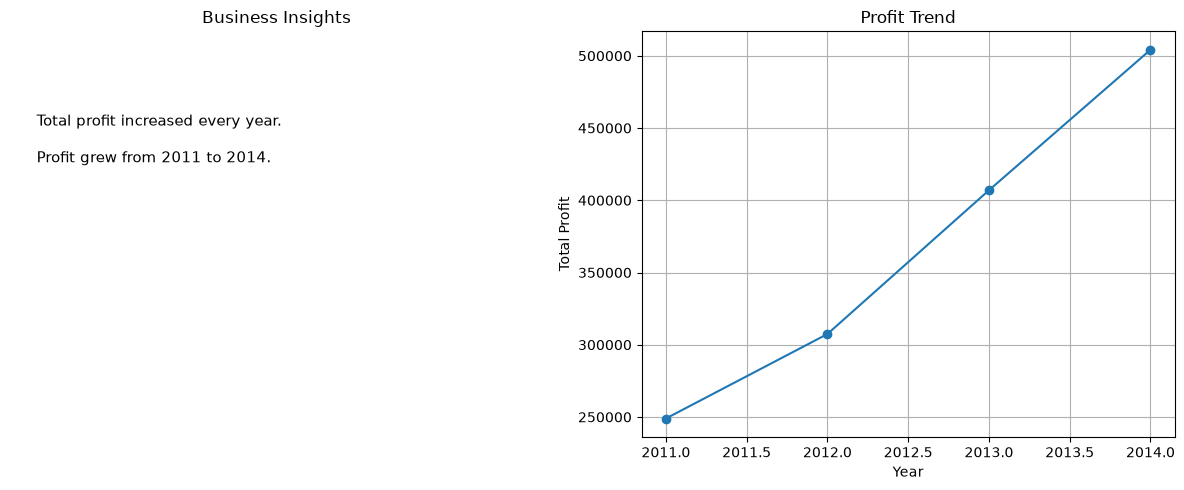

In [51]:
fig, (text_ax, profit_ax) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# Left side: Insights
text_ax.axis("off")
text_ax.set_title("Business Insights")

text_ax.text(
    0.05, 0.8,
    "Total profit increased every year.\n\n"
    "Profit grew from 2011 to 2014.",
    fontsize=11,
    verticalalignment="top"
)

# Right side: Profit Chart
profit_ax.plot(
    yearly_performance.index,
    yearly_performance["Profit"],
    marker="o"
)

profit_ax.set_title("Profit Trend")
profit_ax.set_xlabel("Year")
profit_ax.set_ylabel("Total Profit")
profit_ax.grid()

plt.tight_layout()
plt.show()

In [52]:
category_visual = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

category_visual["Profit Margin"] = (
    category_visual["Profit"] /
    category_visual["Sales"] * 100
)

category_visual

,Sales,Profit,Profit Margin
Category,,,
Furniture,"4,110,874.19","285,204.72",6.94
Office Supplies,"3,787,070.23","518,473.83",13.69
Technology,"4,744,557.50","663,778.73",13.99


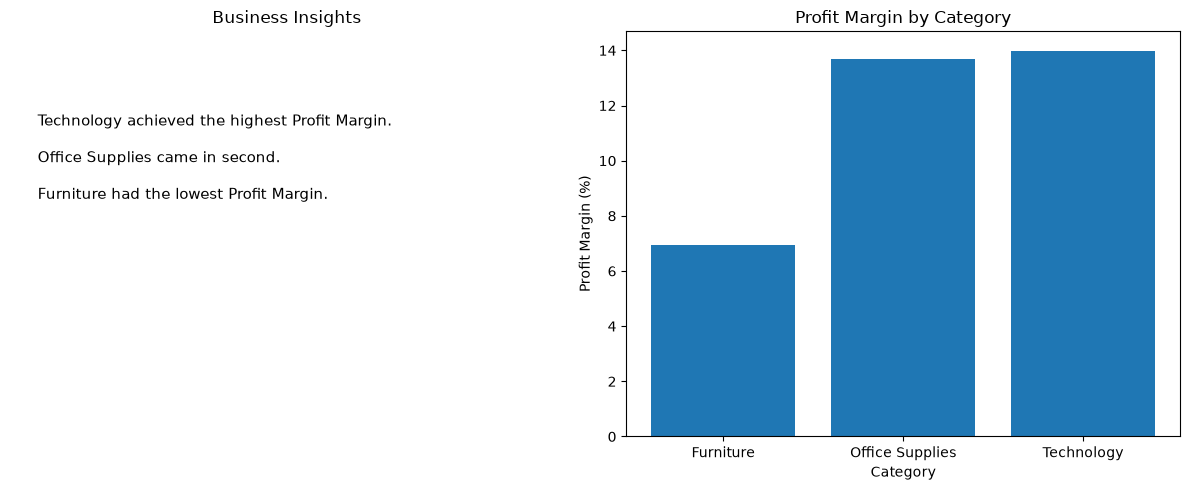

In [53]:
fig, (text_ax, chart_ax) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# Left side: Business Insights
text_ax.axis("off")
text_ax.set_title("Business Insights")

text_ax.text(
    0.05, 0.8,
    "Technology achieved the highest Profit Margin.\n\n"
    "Office Supplies came in second.\n\n"
    "Furniture had the lowest Profit Margin.",
    fontsize=11,
    verticalalignment="top"
)

# Right side: Category Chart
chart_ax.bar(
    category_visual.index,
    category_visual["Profit Margin"]
)

chart_ax.set_title("Profit Margin by Category")
chart_ax.set_xlabel("Category")
chart_ax.set_ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

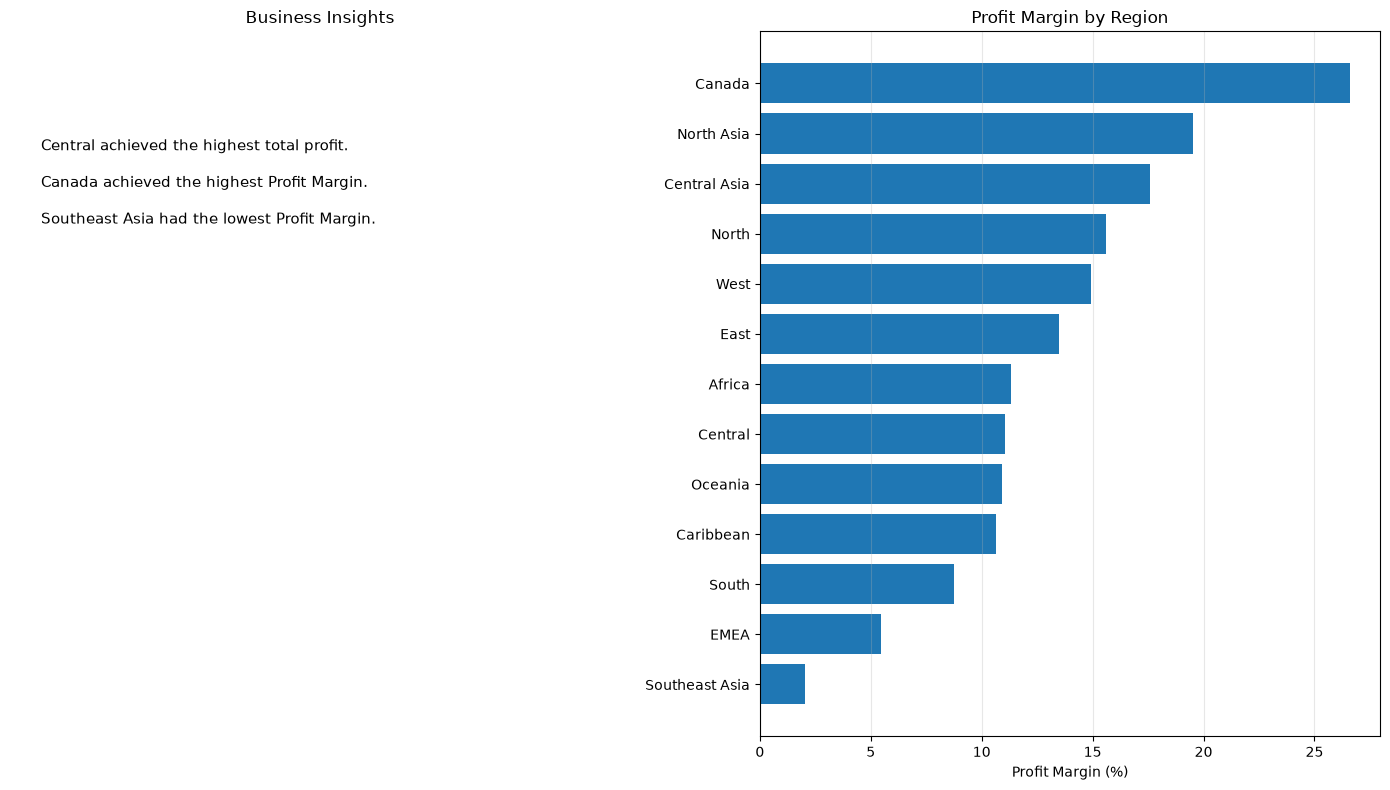

In [54]:
# Sort regions by profit margin
region_visual = region_analysis.sort_values("Profit Margin")

# Create report layout
fig, (text_ax, chart_ax) = plt.subplots(
    1, 2,
    figsize=(14, 8)
)

# Left side: Business Insights
text_ax.axis("off")
text_ax.set_title("Business Insights")

text_ax.text(
    0.05, 0.85,
    "Central achieved the highest total profit.\n\n"
    "Canada achieved the highest Profit Margin.\n\n"
    "Southeast Asia had the lowest Profit Margin.",
    fontsize=11,
    verticalalignment="top"
)

# Right side: Regional Chart
chart_ax.barh(
    region_visual.index,
    region_visual["Profit Margin"]
)

chart_ax.set_title("Profit Margin by Region")
chart_ax.set_xlabel("Profit Margin (%)")
chart_ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

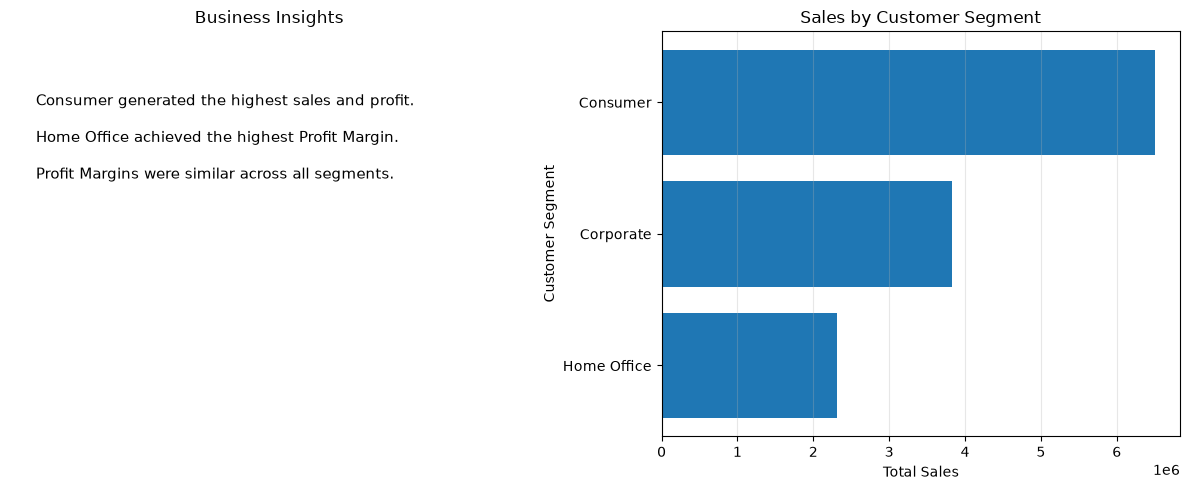

In [55]:
# Sort customer segments by sales
segment_visual = segment_analysis.sort_values("Sales")

# Create report layout
fig, (text_ax, chart_ax) = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

# Left side: Business Insights
text_ax.axis("off")
text_ax.set_title("Business Insights")

text_ax.text(
    0.05, 0.85,
    "Consumer generated the highest sales and profit.\n\n"
    "Home Office achieved the highest Profit Margin.\n\n"
    "Profit Margins were similar across all segments.",
    fontsize=11,
    verticalalignment="top"
)

# Right side: Customer Segment Chart
chart_ax.barh(
    segment_visual.index,
    segment_visual["Sales"]
)

chart_ax.set_title("Sales by Customer Segment")
chart_ax.set_xlabel("Total Sales")
chart_ax.set_ylabel("Customer Segment")
chart_ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()